# Contact distance analysis

In [197]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Protein DBD with DNA

### Load data

In [228]:
wt_dbd_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/004.contacts/pairs_dbd.csv')
    wt_dbd_dfs.append(df)

T419R_dbd_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/004.contacts/pairs_dbd.csv')
    T419R_dbd_dfs.append(df)

In [229]:
wt_dbd_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance
0,1000,190,MET,A,12,DG,D,4.907506
1,1000,190,MET,A,12,DG,D,4.486903
2,1000,192,THR,A,12,DG,D,4.632156
3,1000,192,THR,A,11,DC,D,4.287577
4,1000,192,THR,A,11,DC,D,4.939452


### Preprocessing

Adjust residue numbers.

In [232]:
def adjust_resid(dfs):
    for df in (dfs):
        df["sele1_resid_adj"] = np.where(
            df["sele1_resnm"].str.match(r'^[A-Za-z]{3}$'),
            df["sele1_resid"] + 135,
            df["sele1_resid"]
        )
        df["sele2_resid_adj"] = np.where(
            df["sele2_resnm"].str.match(r'^[A-Za-z]{3}$'),
            df["sele2_resid"] + 135,
            df["sele2_resid"]
    )

In [233]:
adjust_resid(wt_dbd_dfs + T419R_dbd_dfs)

In [234]:
wt_dbd_dfs[0].head()

,frame,sele1_resid,sele1_resnm,sele1_chain,sele2_resid,sele2_resnm,sele2_chain,distance,sele1_resid_adj,sele2_resid_adj
0,1000,190,MET,A,12,DG,D,4.907506,325,12
1,1000,190,MET,A,12,DG,D,4.486903,325,12
2,1000,192,THR,A,12,DG,D,4.632156,327,12
3,1000,192,THR,A,11,DC,D,4.287577,327,11
4,1000,192,THR,A,11,DC,D,4.939452,327,11


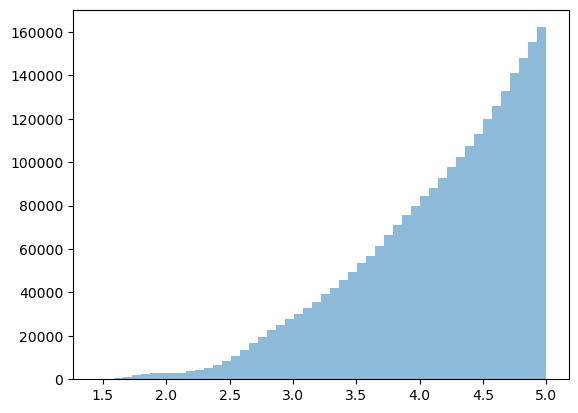

In [276]:
plt.hist(wt_dbd_dfs[0]['distance'], bins=50, alpha=0.5, label='wt', )
plt.show()

Note that each contact is associated with two residues, but no specific atoms. For this reason, a residue pair might be present multiple times in a single frame and, as seen next, dividing the count of a pair by the total number of frames might result in a value higher than 100. 

In [235]:
def aggregate_pairs(df_list):
    combined = pd.concat(df_list)
    agg_df = combined.groupby(['sele1_resnm', 'sele1_resid_adj', 'sele1_chain', 
                               'sele2_resnm', 'sele2_resid_adj', 'sele2_chain']).size().reset_index(name='count')
    
    return agg_df

In [236]:
wt_dbd_agg = aggregate_pairs(wt_dbd_dfs)
T419R_dbd_agg = aggregate_pairs(T419R_dbd_dfs)

In [237]:
wt_dbd_agg.sort_values('count', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count
36,ARG,418,B,DG,19,C,283033
302,SER,459,A,DT,8,C,278783
38,ARG,418,B,DT,7,D,257178
114,GLN,463,A,DT,7,C,202698
391,VAL,339,B,DC,11,C,178984
337,THR,327,A,DC,11,D,168211
34,ARG,418,B,DC,20,C,167178
26,ARG,418,A,DG,20,D,159261
415,VAL,461,B,DG,13,C,142352
89,ASN,460,B,DT,8,D,125384


In [238]:
wt_dbd_agg["count_avg"] = wt_dbd_agg["count"] / (len(wt_dbd_dfs)* 1000)
T419R_dbd_agg["count_avg"] = T419R_dbd_agg["count"] / (len(T419R_dbd_dfs)* 1000)

In [239]:
wt_dbd_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,count_avg
36,ARG,418,B,DG,19,C,283033,94.344333
302,SER,459,A,DT,8,C,278783,92.927667
38,ARG,418,B,DT,7,D,257178,85.726000
114,GLN,463,A,DT,7,C,202698,67.566000
391,VAL,339,B,DC,11,C,178984,59.661333
337,THR,327,A,DC,11,D,168211,56.070333
34,ARG,418,B,DC,20,C,167178,55.726000
26,ARG,418,A,DG,20,D,159261,53.087000
415,VAL,461,B,DG,13,C,142352,47.450667
89,ASN,460,B,DT,8,D,125384,41.794667


In [240]:
T419R_dbd_agg.sort_values('count_avg', ascending=False).head(10)

,sele1_resnm,sele1_resid_adj,sele1_chain,sele2_resnm,sele2_resid_adj,sele2_chain,count,count_avg
50,ARG,419,A,DG,20,D,375678,125.226000
61,ARG,419,B,DG,19,C,322140,107.380000
365,VAL,339,B,DC,11,C,317278,105.759333
305,SER,459,B,DT,8,D,256219,85.406333
36,ARG,418,B,DC,20,C,243926,81.308667
49,ARG,419,A,DG,6,C,217687,72.562333
287,PRO,423,A,DG,6,C,211016,70.338667
62,ARG,419,B,DT,7,D,207056,69.018667
63,ARG,419,B,DT,8,D,190097,63.365667
128,GLN,463,B,DT,7,D,167593,55.864333


### Comparison

In [241]:
def pivotdf(df):
    pivot = df.pivot_table(values='count_avg', 
                          index='sele2_resid_adj', 
                          columns='sele1_resid_adj', 
                          aggfunc='mean')
    return pivot

In [242]:
wt_dbd_pivot = pivotdf(wt_dbd_agg)
mut_dbd_pivot = pivotdf(T419R_dbd_agg)

In [243]:
wt_dbd_pivot.head()

sele1_resid_adj,325,326,327,328,329,330,331,336,337,338,...,429,457,458,459,460,461,462,463,464,466
sele2_resid_adj,,,,,,,,,,,,,,,,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.002667,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0005,NaN,0.033167,1.773167,NaN,0.0015


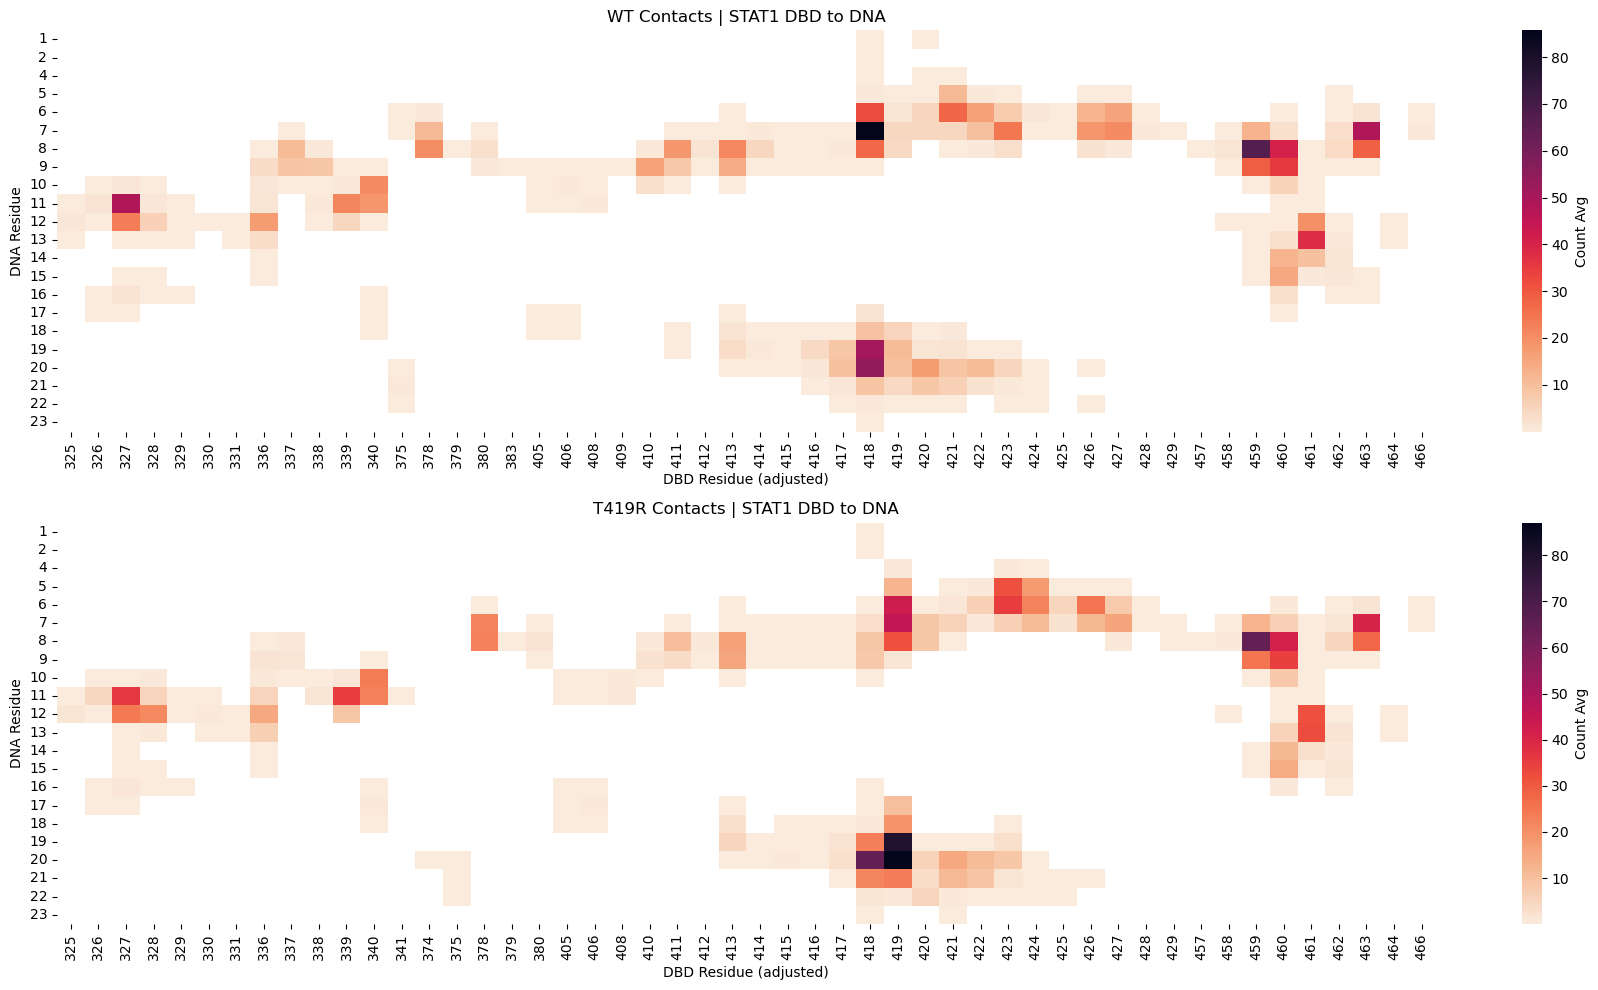

In [290]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_dbd_pivot, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 DBD to DNA')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T419R heatmap
sns.heatmap(mut_dbd_pivot, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('T419R Contacts | STAT1 DBD to DNA')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

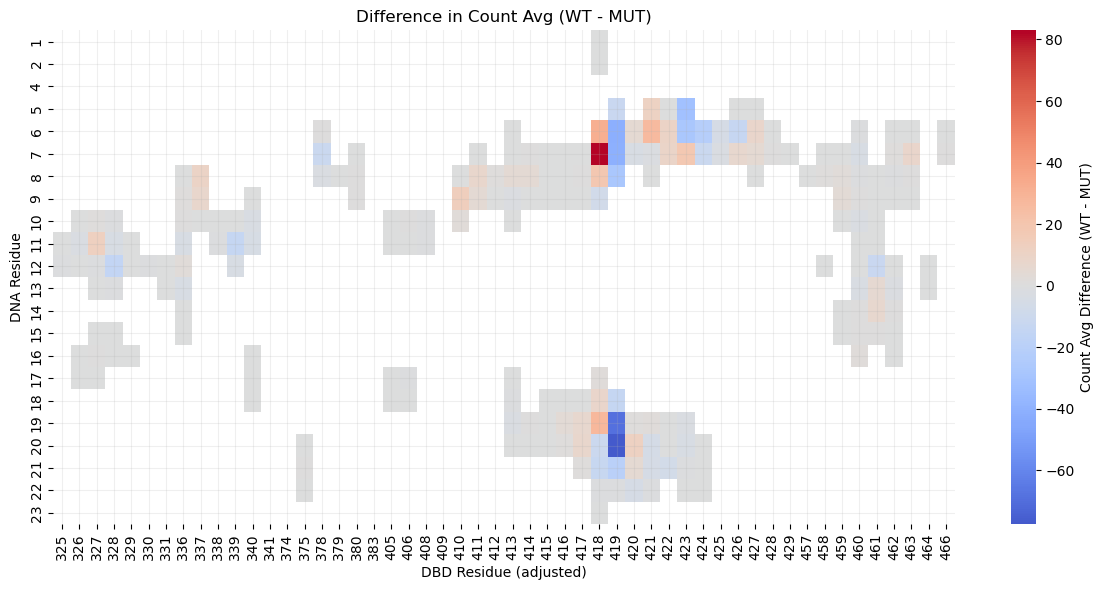

In [245]:
diff_dbd_pivot = wt_dbd_pivot - mut_dbd_pivot

plt.figure(figsize=(12, 6))

sns.heatmap(diff_dbd_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT)')
plt.xlabel('DBD Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

#### By monomer

In [247]:
wt_dbd_agg['sele1_chain'].value_counts()

sele1_chain
A    210
B    209
Name: count, dtype: int64

In [248]:
wt_dbd_agg_monoA = wt_dbd_agg[wt_dbd_agg['sele1_chain'] == 'A']
wt_dbd_agg_monoB = wt_dbd_agg[wt_dbd_agg['sele1_chain'] == 'B']

In [249]:
T419R_dbd_agg['sele1_chain'].value_counts()

sele1_chain
A    202
B    193
Name: count, dtype: int64

In [250]:
T419R_dbd_agg_monoA = T419R_dbd_agg[T419R_dbd_agg['sele1_chain'] == 'A']
T419R_dbd_agg_monoB = T419R_dbd_agg[T419R_dbd_agg['sele1_chain'] == 'B']

In [251]:
wt_dbd_monoA_pivot = pivotdf(wt_dbd_agg_monoA)
wt_dbd_monoB_pivot = pivotdf(wt_dbd_agg_monoB)
mut_dbd_monoA_pivot = pivotdf(T419R_dbd_agg_monoA)
mut_dbd_monoB_pivot = pivotdf(T419R_dbd_agg_monoB)

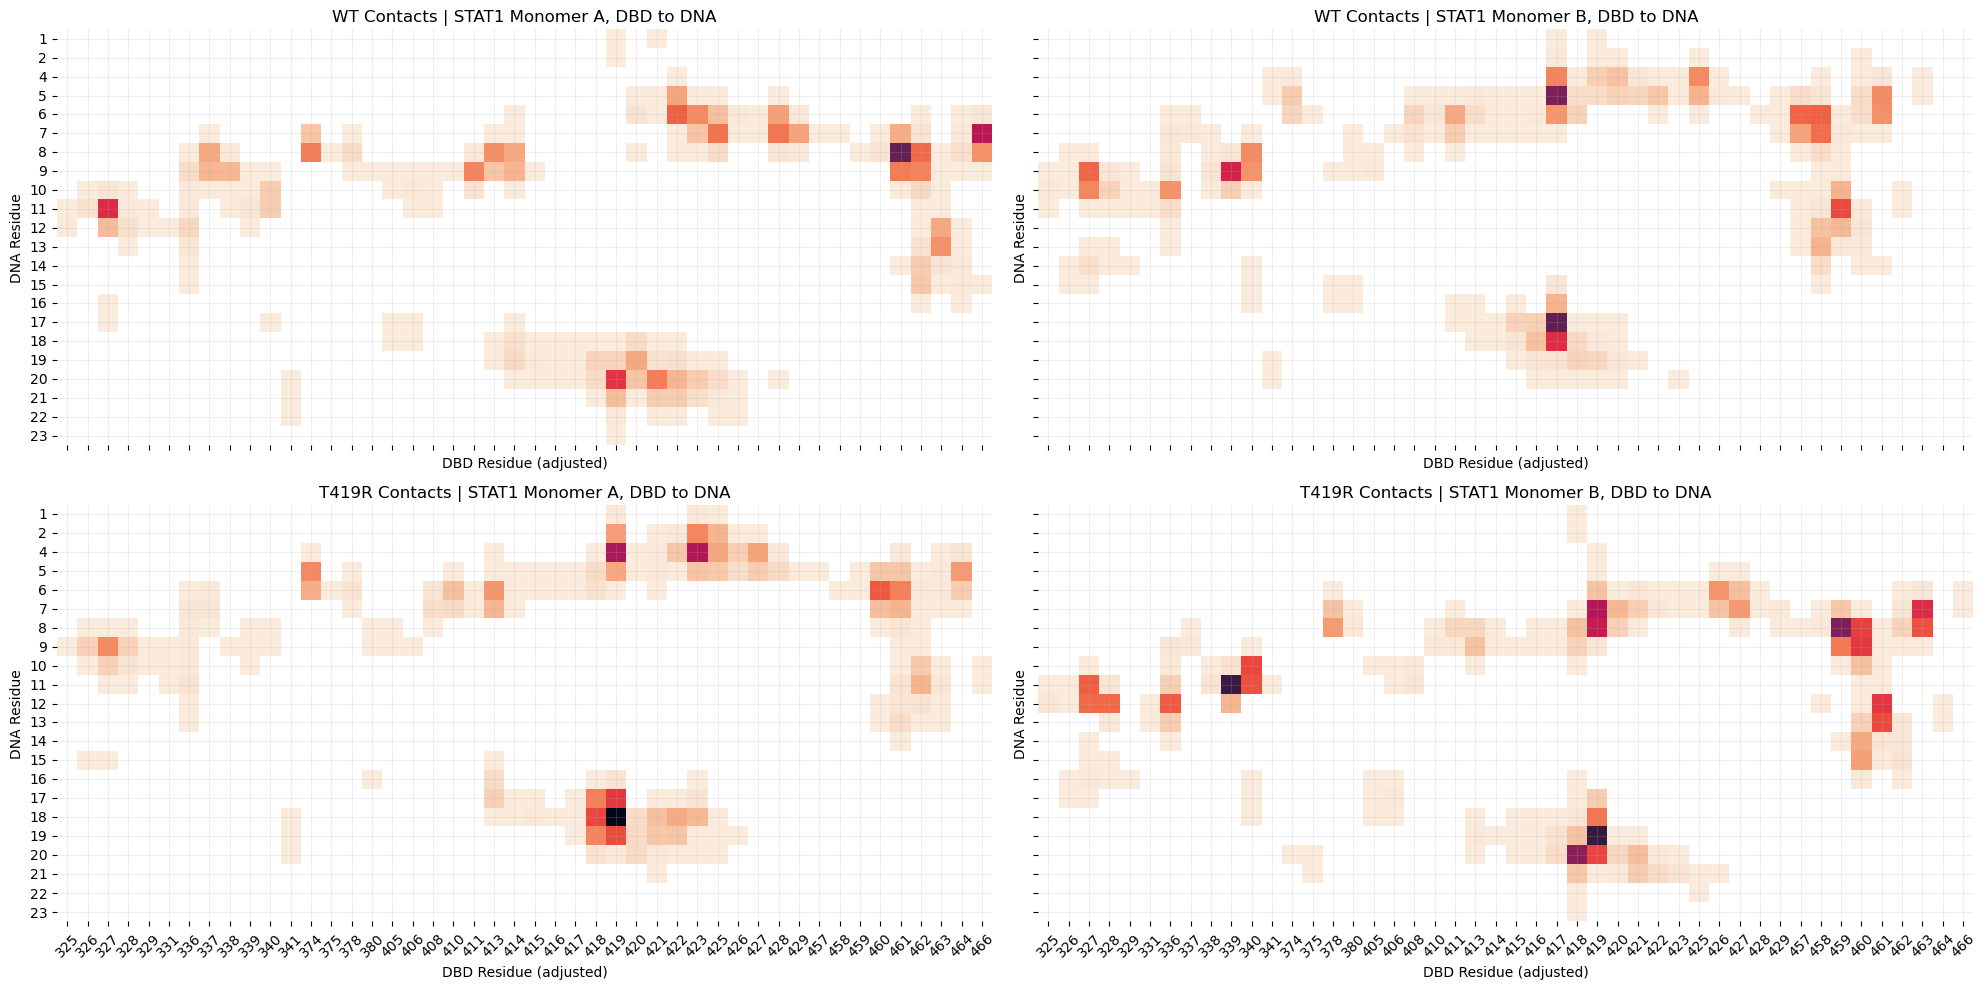

In [303]:
# Find global min and max
all_data = [
    wt_dbd_monoA_pivot.values,
    wt_dbd_monoB_pivot.values,
    mut_dbd_monoA_pivot.values,
    mut_dbd_monoB_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (wt_dbd_monoA_pivot, ax1, 'WT Contacts | STAT1 Monomer A, DBD to DNA'),
    (wt_dbd_monoB_pivot, ax2, 'WT Contacts | STAT1 Monomer B, DBD to DNA'),
    (mut_dbd_monoA_pivot, ax3, 'T419R Contacts | STAT1 Monomer A, DBD to DNA'),
    (mut_dbd_monoB_pivot, ax4, 'T419R Contacts | STAT1 Monomer B, DBD to DNA')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)

# Rotate x-axis labels for all axes
for ax in axes.flatten():
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

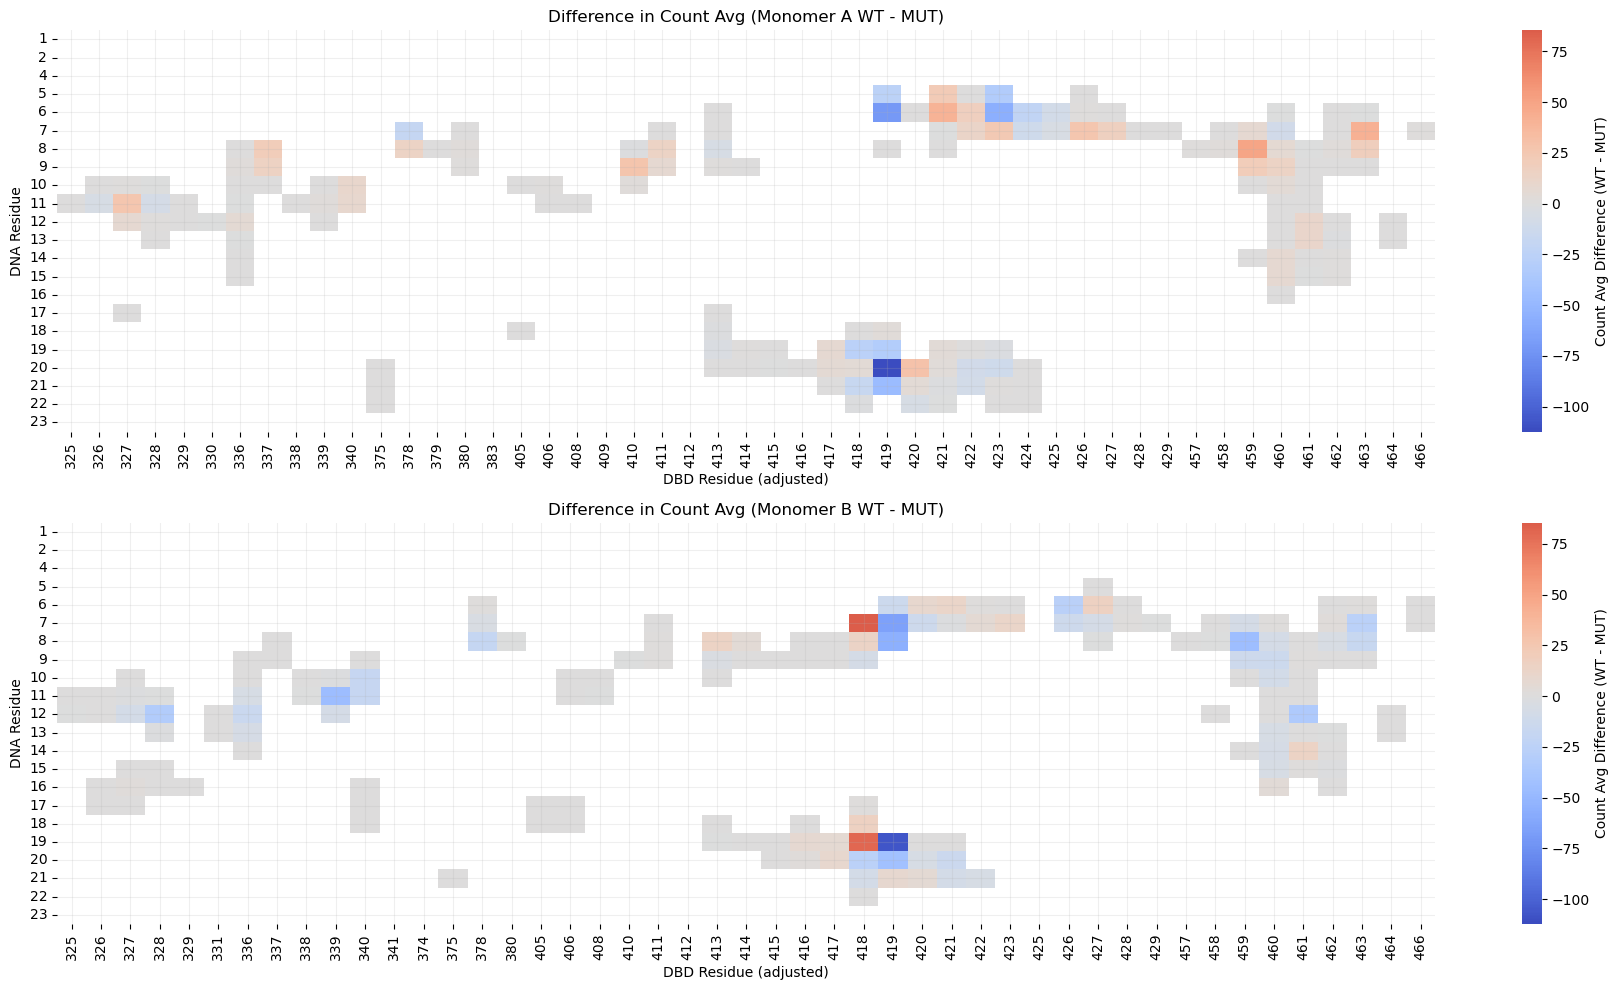

In [263]:
diff_dbd_monoA_pivot = wt_dbd_monoA_pivot - mut_dbd_monoA_pivot
diff_dbd_monoB_pivot = wt_dbd_monoB_pivot - mut_dbd_monoB_pivot

# Find global min and max
all_data = [
    diff_dbd_monoA_pivot.values,
    diff_dbd_monoB_pivot.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# Monomer A
sns.heatmap(diff_dbd_monoA_pivot, cmap='coolwarm', center=0, ax=ax1, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
ax1.set_title('Difference in Count Avg (Monomer A WT - MUT)')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha = 0.2)

# Monomer B
sns.heatmap(diff_dbd_monoB_pivot, cmap='coolwarm', center=0, ax=ax2, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
ax2.set_title('Difference in Count Avg (Monomer B WT - MUT)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

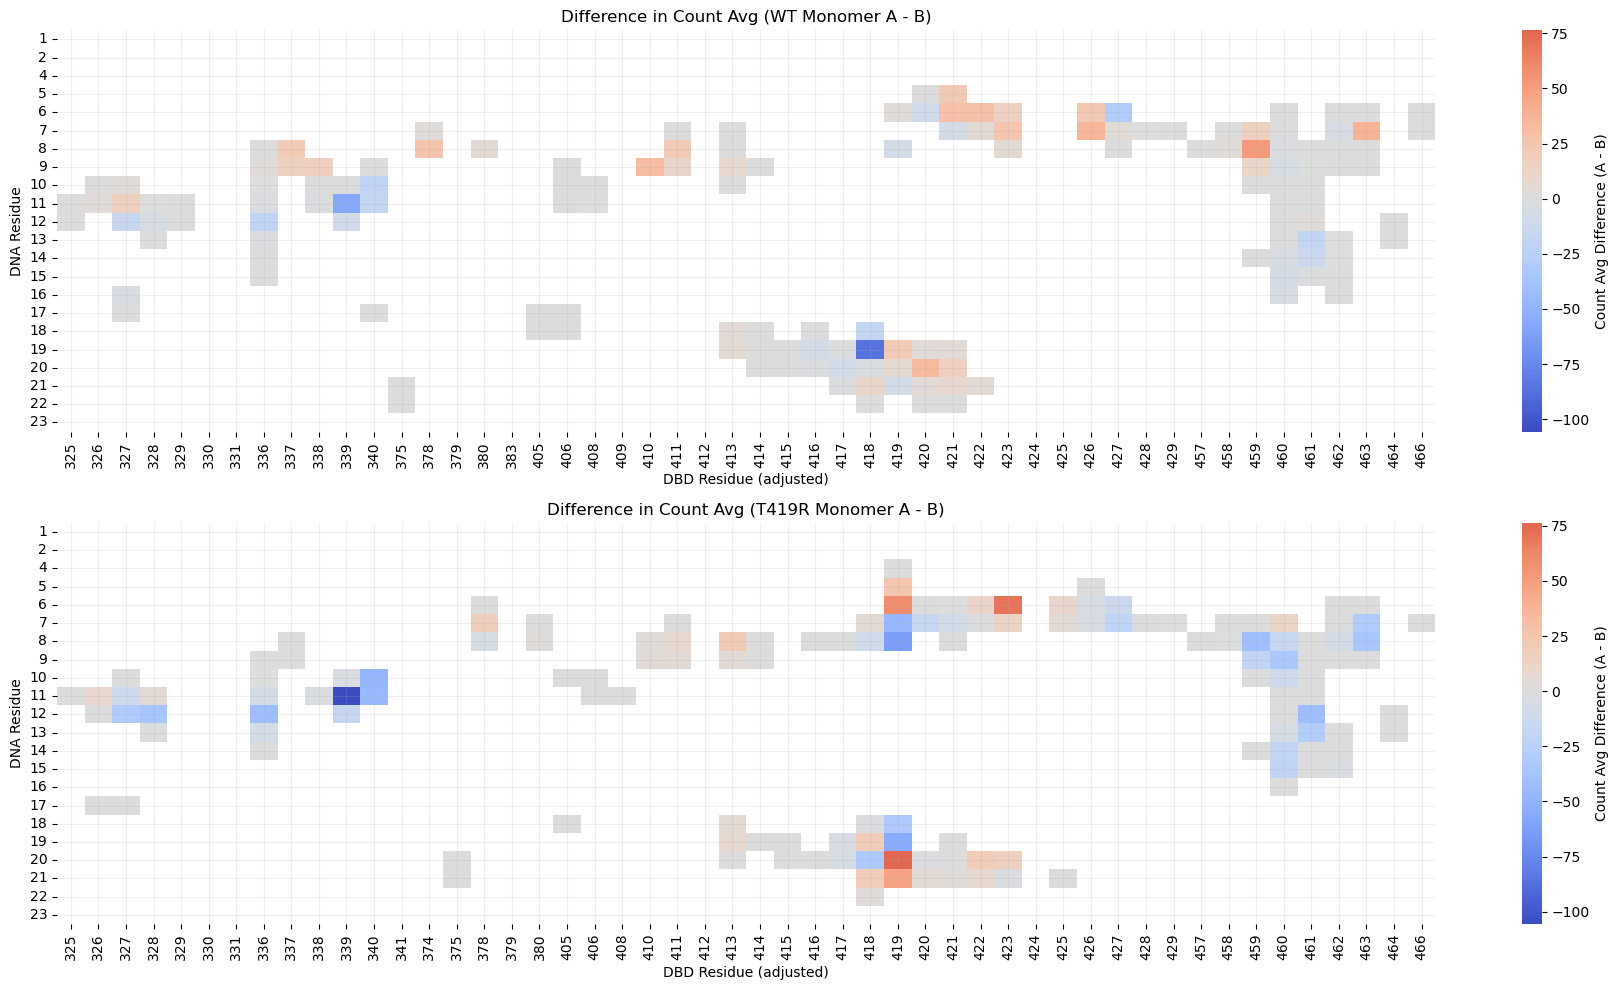

In [277]:
diff_dbd_wt_pivot = wt_dbd_monoA_pivot - wt_dbd_monoB_pivot
diff_dbd_mut_pivot = mut_dbd_monoA_pivot - mut_dbd_monoB_pivot

# Find global min and max
all_data = [
    diff_dbd_wt_pivot.values,
    diff_dbd_mut_pivot.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT
sns.heatmap(diff_dbd_wt_pivot, cmap='coolwarm', center=0, ax=ax1, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (A - B)'})
ax1.set_title('Difference in Count Avg (WT Monomer A - B)')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')
ax1.grid(alpha = 0.2)

# Monomer B
sns.heatmap(diff_dbd_mut_pivot, cmap='coolwarm', center=0, ax=ax2, vmin=global_min, vmax=global_max, cbar_kws={'label': 'Count Avg Difference (A - B)'})
ax2.set_title('Difference in Count Avg (T419R Monomer A - B)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')
ax2.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

#### By monomer and DNA strand

In [ ]:
wt_dbd_agg_monoA_C = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'A') & (wt_dbd_agg['sele2_chain'] == 'C')]
wt_dbd_agg_monoA_D = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'A') & (wt_dbd_agg['sele2_chain'] == 'D')]
wt_dbd_agg_monoB_C = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'B') & (wt_dbd_agg['sele2_chain'] == 'C')]
wt_dbd_agg_monoB_D = wt_dbd_agg[(wt_dbd_agg['sele1_chain'] == 'B') & (wt_dbd_agg['sele2_chain'] == 'D')]

wt_dbd_monoA_C_pivot = pivotdf(wt_dbd_agg_monoA_C)
wt_dbd_monoA_D_pivot = pivotdf(wt_dbd_agg_monoA_D)
wt_dbd_monoB_C_pivot = pivotdf(wt_dbd_agg_monoB_C)
wt_dbd_monoB_D_pivot = pivotdf(wt_dbd_agg_monoB_D)

T419R_dbd_agg_monoA_C = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'A') & (T419R_dbd_agg['sele2_chain'] == 'C')]
T419R_dbd_agg_monoA_D = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'A') & (T419R_dbd_agg['sele2_chain'] == 'D')]
T419R_dbd_agg_monoB_C = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'B') & (T419R_dbd_agg['sele2_chain'] == 'C')]
T419R_dbd_agg_monoB_D = T419R_dbd_agg[(T419R_dbd_agg['sele1_chain'] == 'B') & (T419R_dbd_agg['sele2_chain'] == 'D')]

mut_dbd_monoA_C_pivot = pivotdf(T419R_dbd_agg_monoA_C)
mut_dbd_monoA_D_pivot = pivotdf(T419R_dbd_agg_monoA_D)
mut_dbd_monoB_C_pivot = pivotdf(T419R_dbd_agg_monoB_C)
mut_dbd_monoB_D_pivot = pivotdf(T419R_dbd_agg_monoB_D)

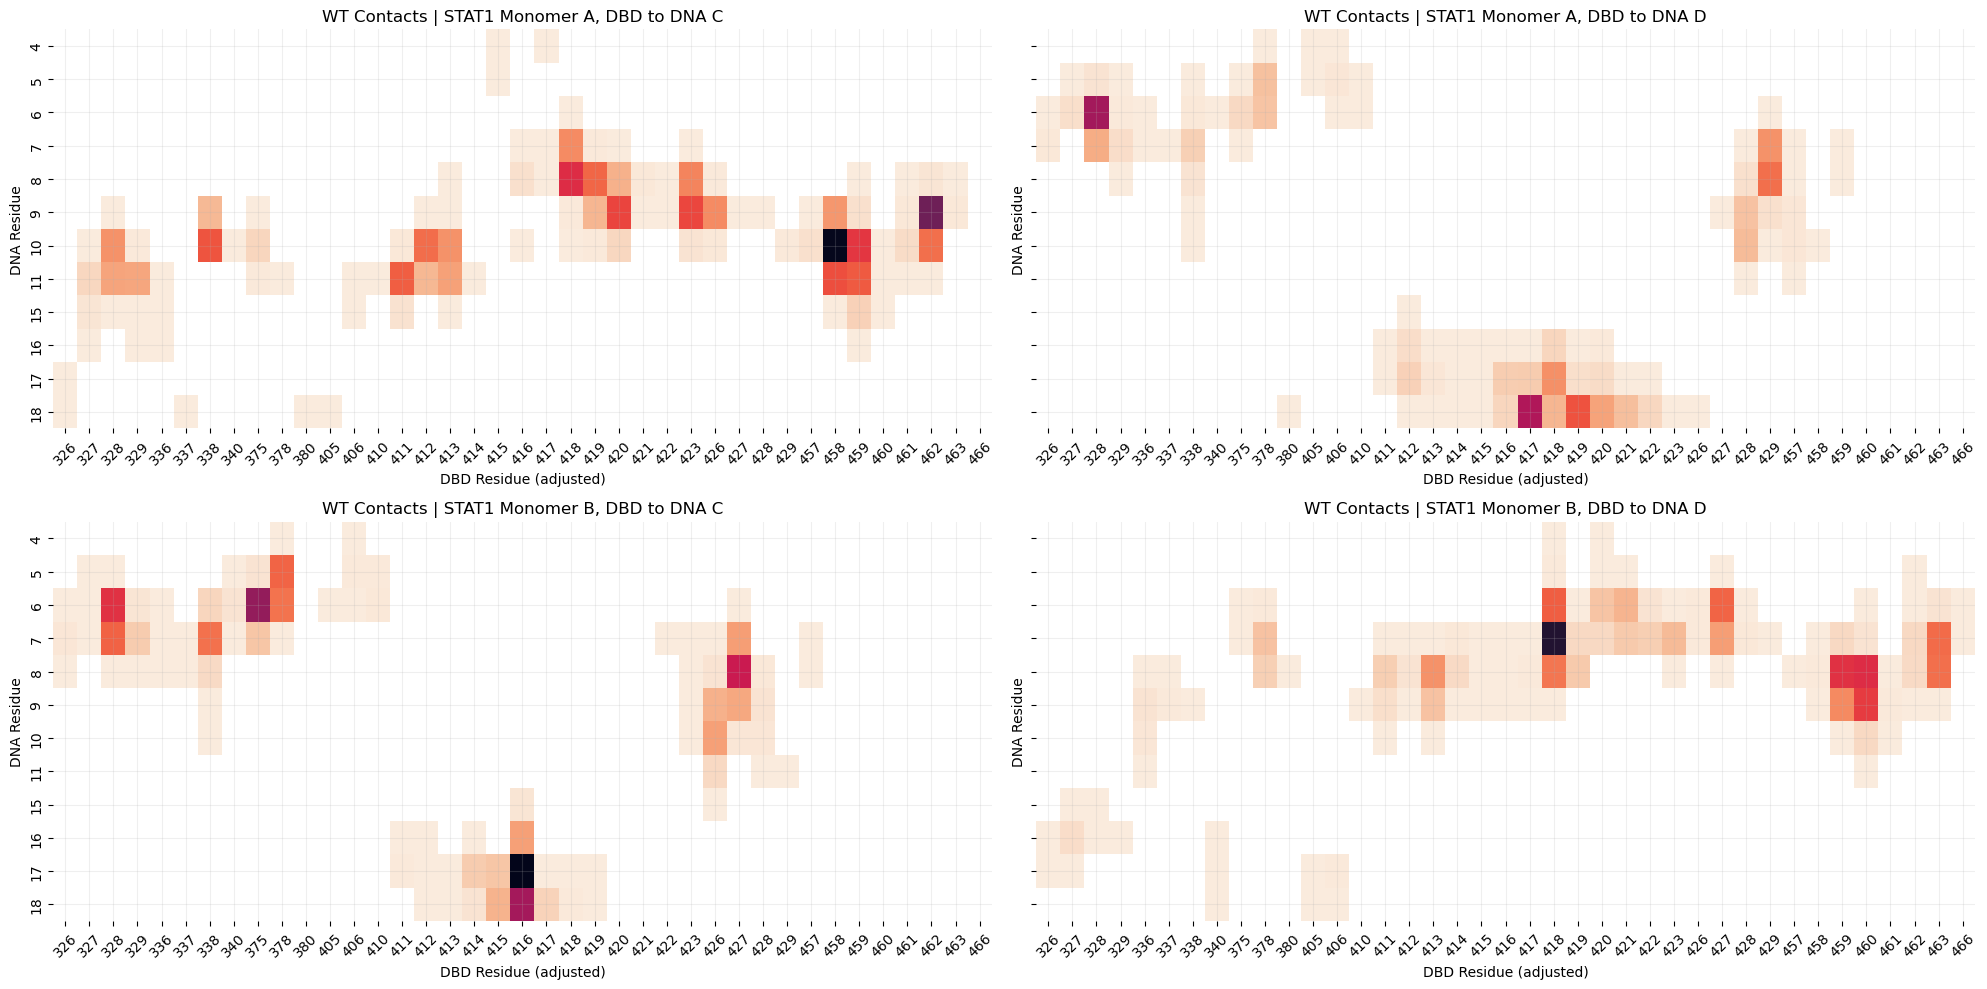

In [313]:
# Find global min and max
all_data = [
    wt_dbd_monoA_C_pivot.values,
    wt_dbd_monoA_D_pivot.values,
    wt_dbd_monoB_C_pivot.values,
    wt_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (wt_dbd_monoA_C_pivot, ax1, 'WT Contacts | STAT1 Monomer A, DBD to DNA C'),
    (wt_dbd_monoA_D_pivot, ax2, 'WT Contacts | STAT1 Monomer A, DBD to DNA D'),
    (wt_dbd_monoB_C_pivot, ax3, 'WT Contacts | STAT1 Monomer B, DBD to DNA C'),
    (wt_dbd_monoB_D_pivot, ax4, 'WT Contacts | STAT1 Monomer B, DBD to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

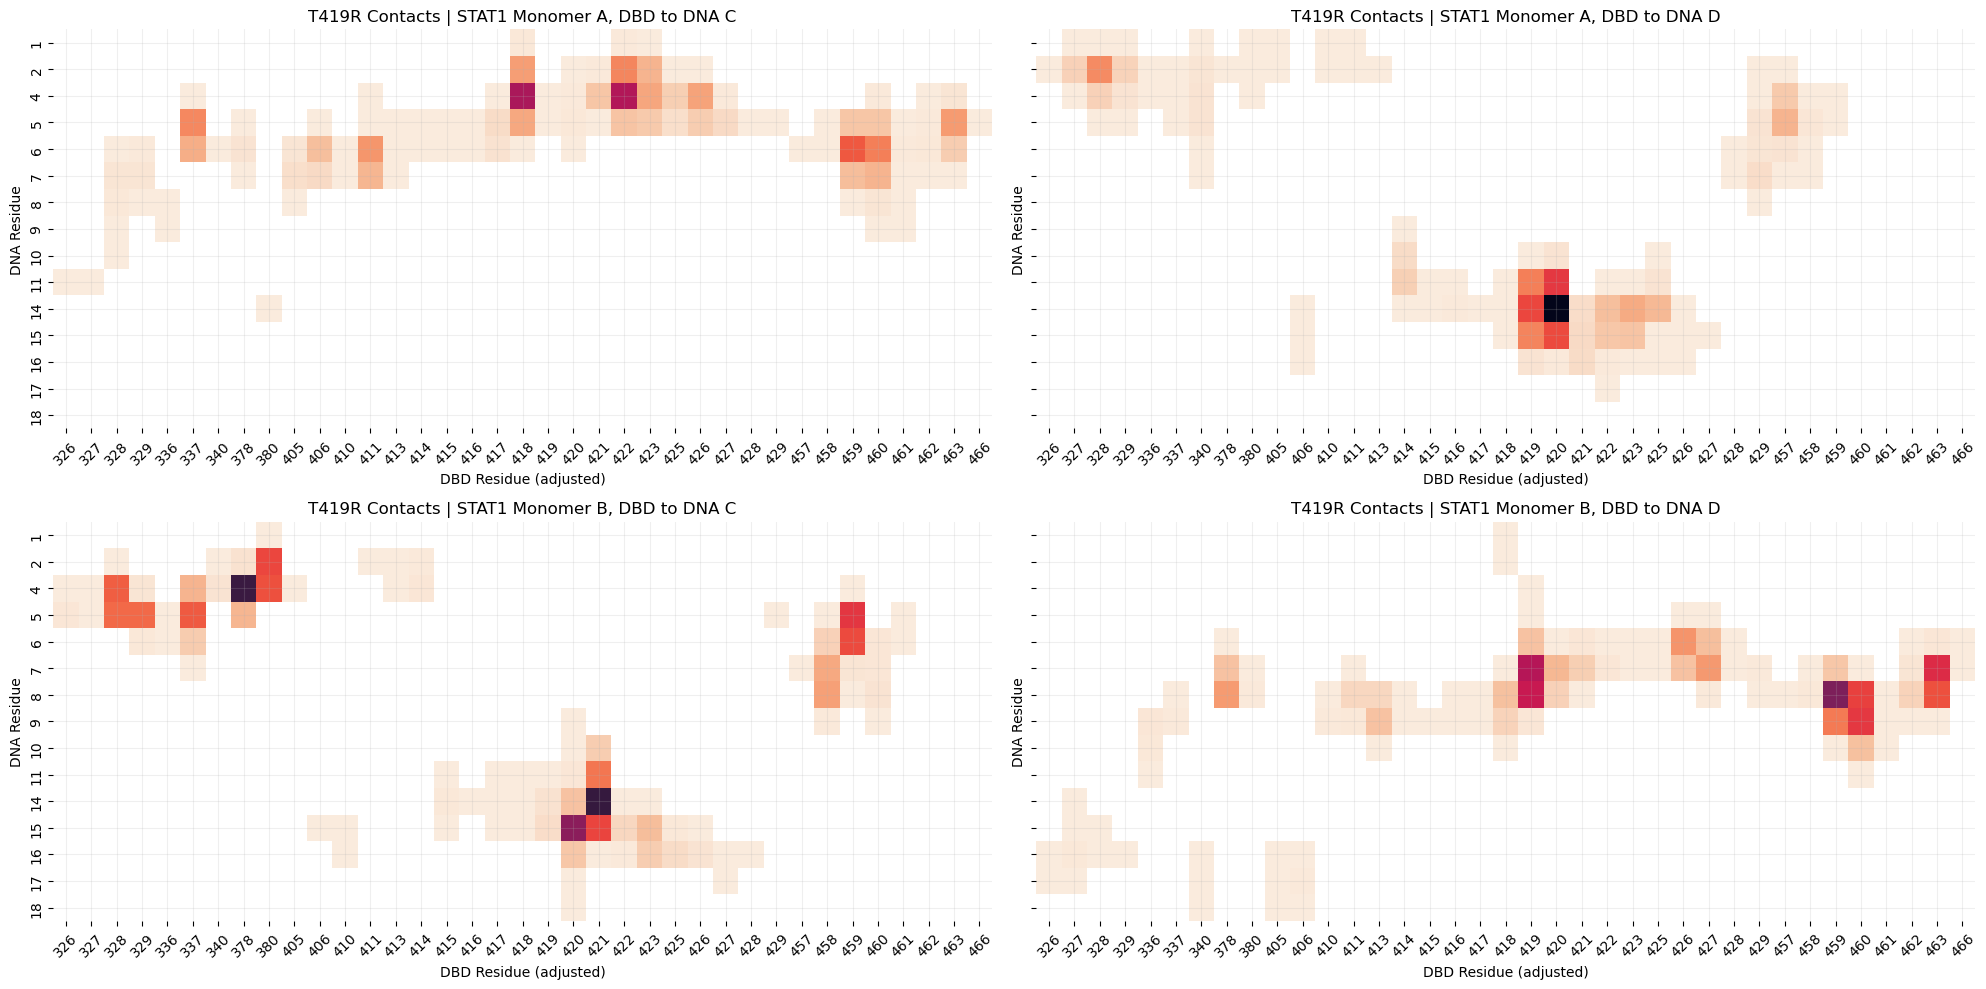

In [312]:
# Find global min and max
all_data = [
    mut_dbd_monoA_C_pivot.values,
    mut_dbd_monoA_D_pivot.values,
    mut_dbd_monoB_C_pivot.values,
    mut_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(20, 10), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()
plots = [
    (mut_dbd_monoA_C_pivot, ax1, 'T419R Contacts | STAT1 Monomer A, DBD to DNA C'),
    (mut_dbd_monoA_D_pivot, ax2, 'T419R Contacts | STAT1 Monomer A, DBD to DNA D'),
    (mut_dbd_monoB_C_pivot, ax3, 'T419R Contacts | STAT1 Monomer B, DBD to DNA C'),
    (mut_dbd_monoB_D_pivot, ax4, 'T419R Contacts | STAT1 Monomer B, DBD to DNA D')
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

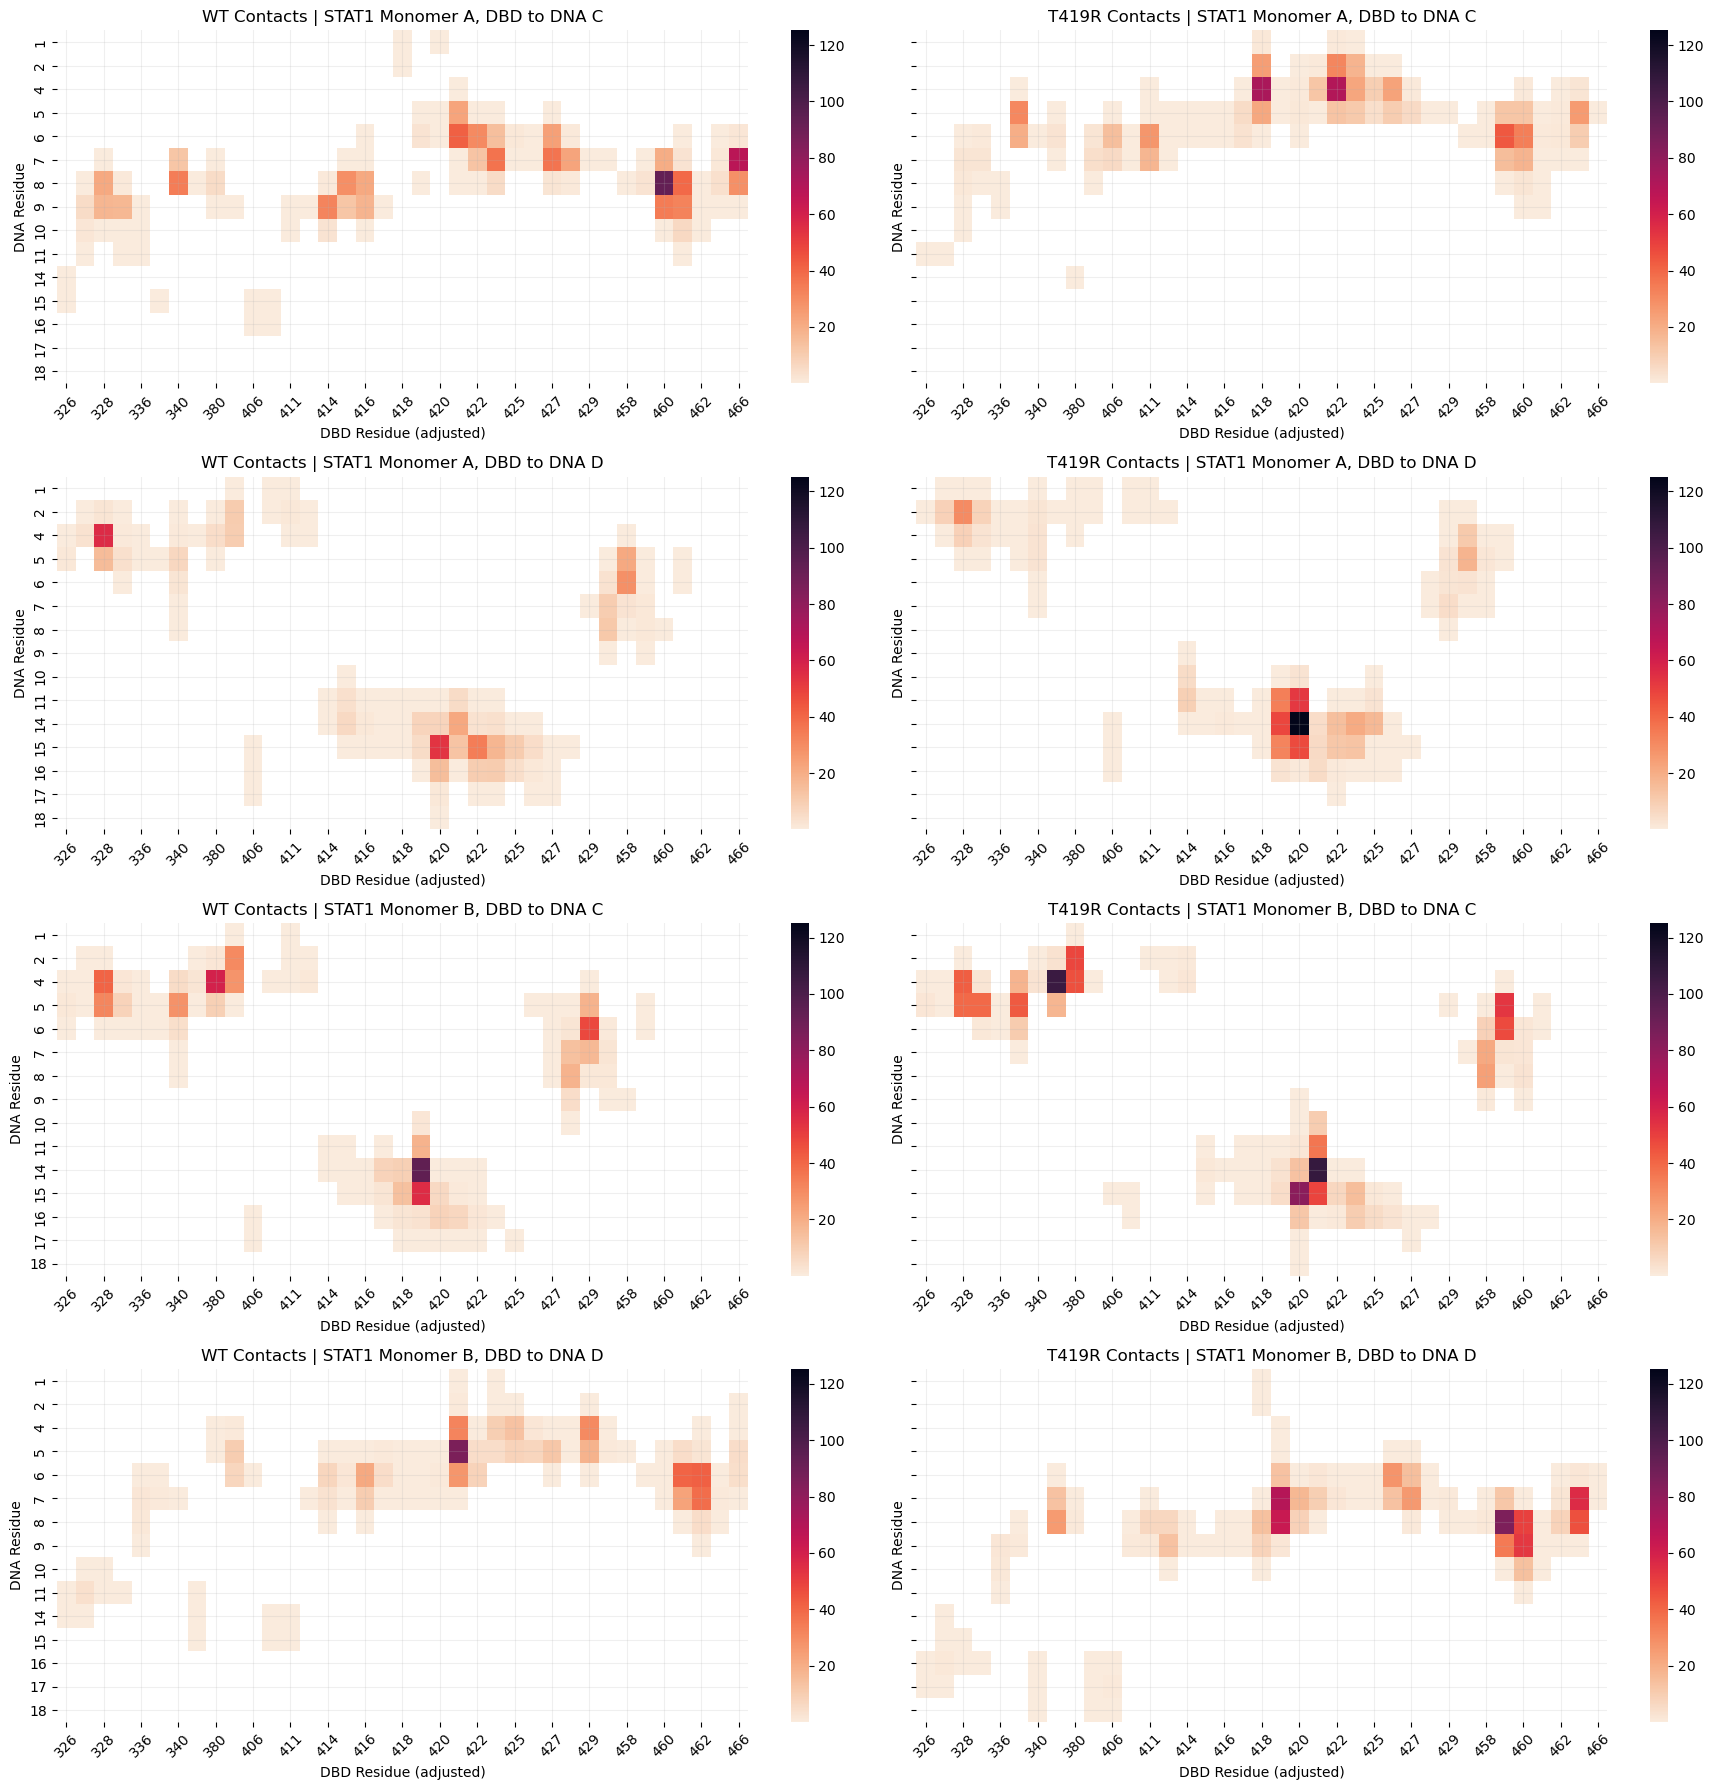

In [321]:
# Find global min and max
all_data = [
    wt_dbd_monoA_C_pivot.values,
    wt_dbd_monoA_D_pivot.values,
    wt_dbd_monoB_C_pivot.values,
    wt_dbd_monoB_D_pivot.values,
    mut_dbd_monoA_C_pivot.values,
    mut_dbd_monoA_D_pivot.values,
    mut_dbd_monoB_C_pivot.values,
    mut_dbd_monoB_D_pivot.values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(4, 2, figsize=(18, 18), sharey=True, sharex=True)
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.flatten()

plots = [
    (wt_dbd_monoA_C_pivot, ax1, 'WT Contacts | STAT1 Monomer A, DBD to DNA C'),
    (mut_dbd_monoA_C_pivot, ax2, 'T419R Contacts | STAT1 Monomer A, DBD to DNA C'),
    (wt_dbd_monoA_D_pivot, ax3, 'WT Contacts | STAT1 Monomer A, DBD to DNA D'),
    (mut_dbd_monoA_D_pivot, ax4, 'T419R Contacts | STAT1 Monomer A, DBD to DNA D'),
    (wt_dbd_monoB_C_pivot, ax5, 'WT Contacts | STAT1 Monomer B, DBD to DNA C'),
    (mut_dbd_monoB_C_pivot, ax6, 'T419R Contacts | STAT1 Monomer B, DBD to DNA C'),
    (wt_dbd_monoB_D_pivot, ax7, 'WT Contacts | STAT1 Monomer B, DBD to DNA D'),
    (mut_dbd_monoB_D_pivot, ax8, 'T419R Contacts | STAT1 Monomer B, DBD to DNA D'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='rocket_r', 
        ax=ax, 
        cbar=False, 
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

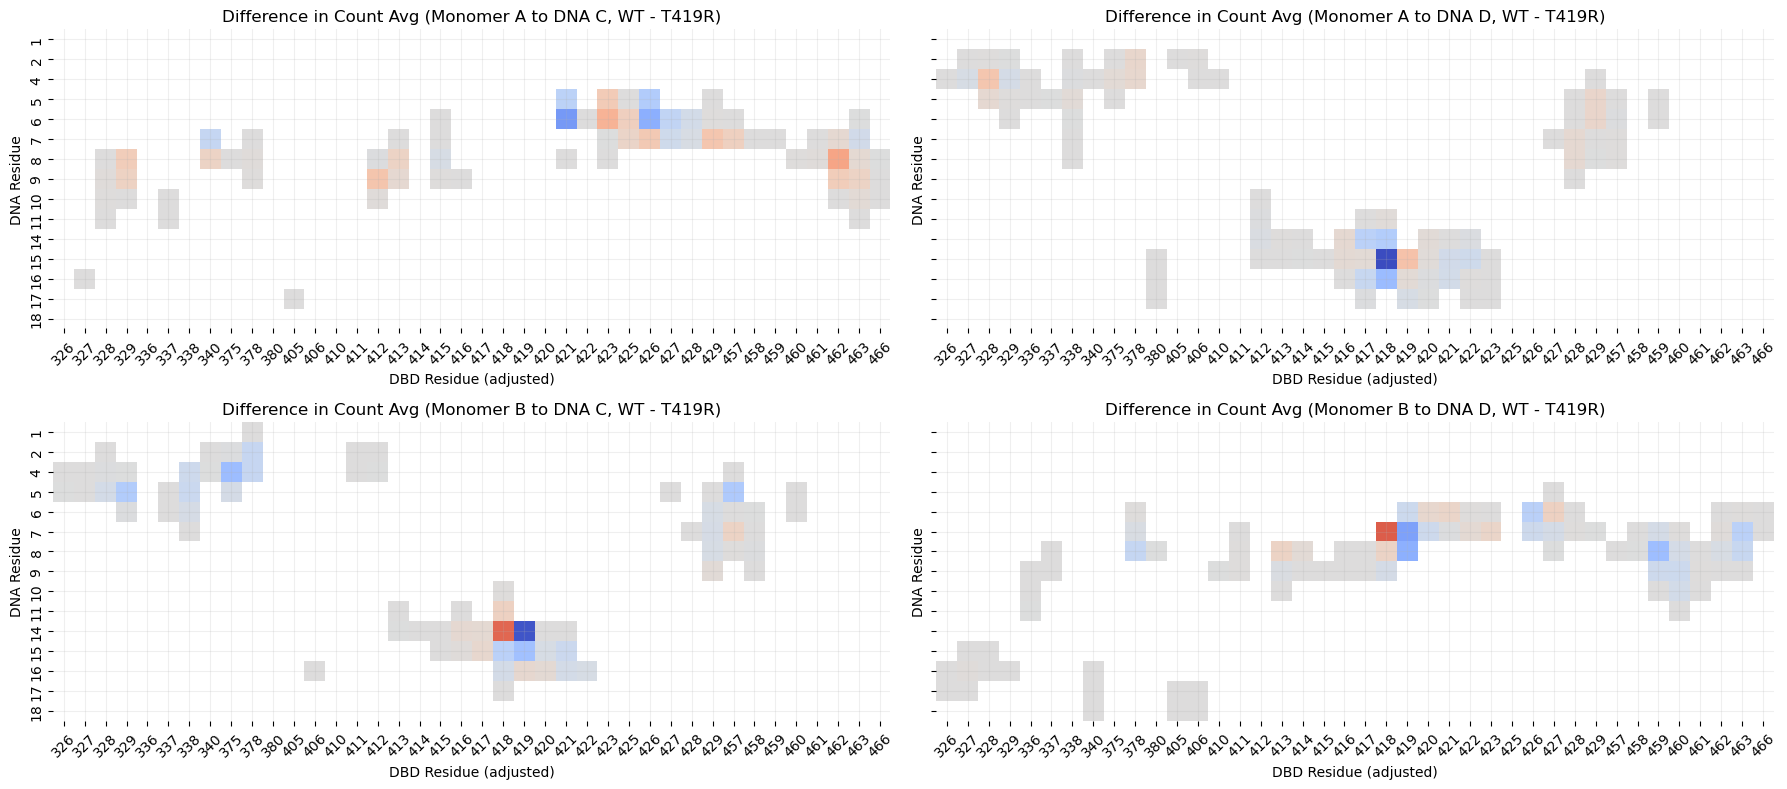

In [322]:
diff_dbd_wt_monoA_C_mut_monoA_C = wt_dbd_monoA_C_pivot - mut_dbd_monoA_C_pivot
diff_dbd_wt_monoA_D_mut_monoA_D = wt_dbd_monoA_D_pivot - mut_dbd_monoA_D_pivot
diff_dbd_wt_monoB_C_mut_monoB_C = wt_dbd_monoB_C_pivot - mut_dbd_monoB_C_pivot
diff_dbd_wt_monoB_D_mut_monoB_D = wt_dbd_monoB_D_pivot - mut_dbd_monoB_D_pivot

# Find global min and max
all_data = [
    diff_dbd_wt_monoA_C_mut_monoA_C.values,
    diff_dbd_wt_monoA_D_mut_monoA_D.values,
    diff_dbd_wt_monoB_C_mut_monoB_C.values,
    diff_dbd_wt_monoB_D_mut_monoB_D.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (diff_dbd_wt_monoA_C_mut_monoA_C, ax1, 'Difference in Count Avg (Monomer A to DNA C, WT - T419R)'),
    (diff_dbd_wt_monoA_D_mut_monoA_D, ax2, 'Difference in Count Avg (Monomer A to DNA D, WT - T419R)'),
    (diff_dbd_wt_monoB_C_mut_monoB_C, ax3, 'Difference in Count Avg (Monomer B to DNA C, WT - T419R)'),
    (diff_dbd_wt_monoB_D_mut_monoB_D, ax4, 'Difference in Count Avg (Monomer B to DNA D, WT - T419R)'),
]

for pivot_df, ax, title in plots:
    sns.heatmap(
        pivot_df, 
        cmap='coolwarm', 
        ax=ax, 
        cbar=False, 
        center=0,
        vmin=global_min, 
        vmax=global_max
    )
    ax.set_title(title)
    ax.set_xlabel('DBD Residue (adjusted)')
    ax.set_ylabel('DNA Residue')
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45, labelbottom=True)

plt.tight_layout()
plt.show()

#### Filter out (potential) hydrogen bonds

A separate analysis focuses on hydrogen bonds, with a distance threshold of < 3.5 Å. Applying a distance filter removes these from the contact results.

In [ ]:
def aggregate_pairs_filter(df_list):
    combined = pd.concat(df_list)
    combined = combined[combined['distance'] > 3.5]
    agg_df = combined.groupby(['sele1_resnm', 'sele1_resid_adj', 
                               'sele2_resnm', 'sele2_resid_adj']).size().reset_index(name='count')
    
    return agg_df

In [213]:
wt_dbd_agg_filtered = aggregate_pairs_filter(wt_dbd_dfs)
T419R_dbd_agg_filtered = aggregate_pairs_filter(T419R_dbd_dfs)

wt_dbd_agg_filtered["count_avg"] = wt_dbd_agg_filtered["count"] / (len(wt_dbd_dfs)* 1000)
T419R_dbd_agg_filtered["count_avg"] = T419R_dbd_agg_filtered["count"] / (len(T419R_dbd_dfs)* 1000)

wt_dbd_pivot_filtered = pivotdf(wt_dbd_agg_filtered)
mut_dbd_pivot_filtered = pivotdf(T419R_dbd_agg_filtered)

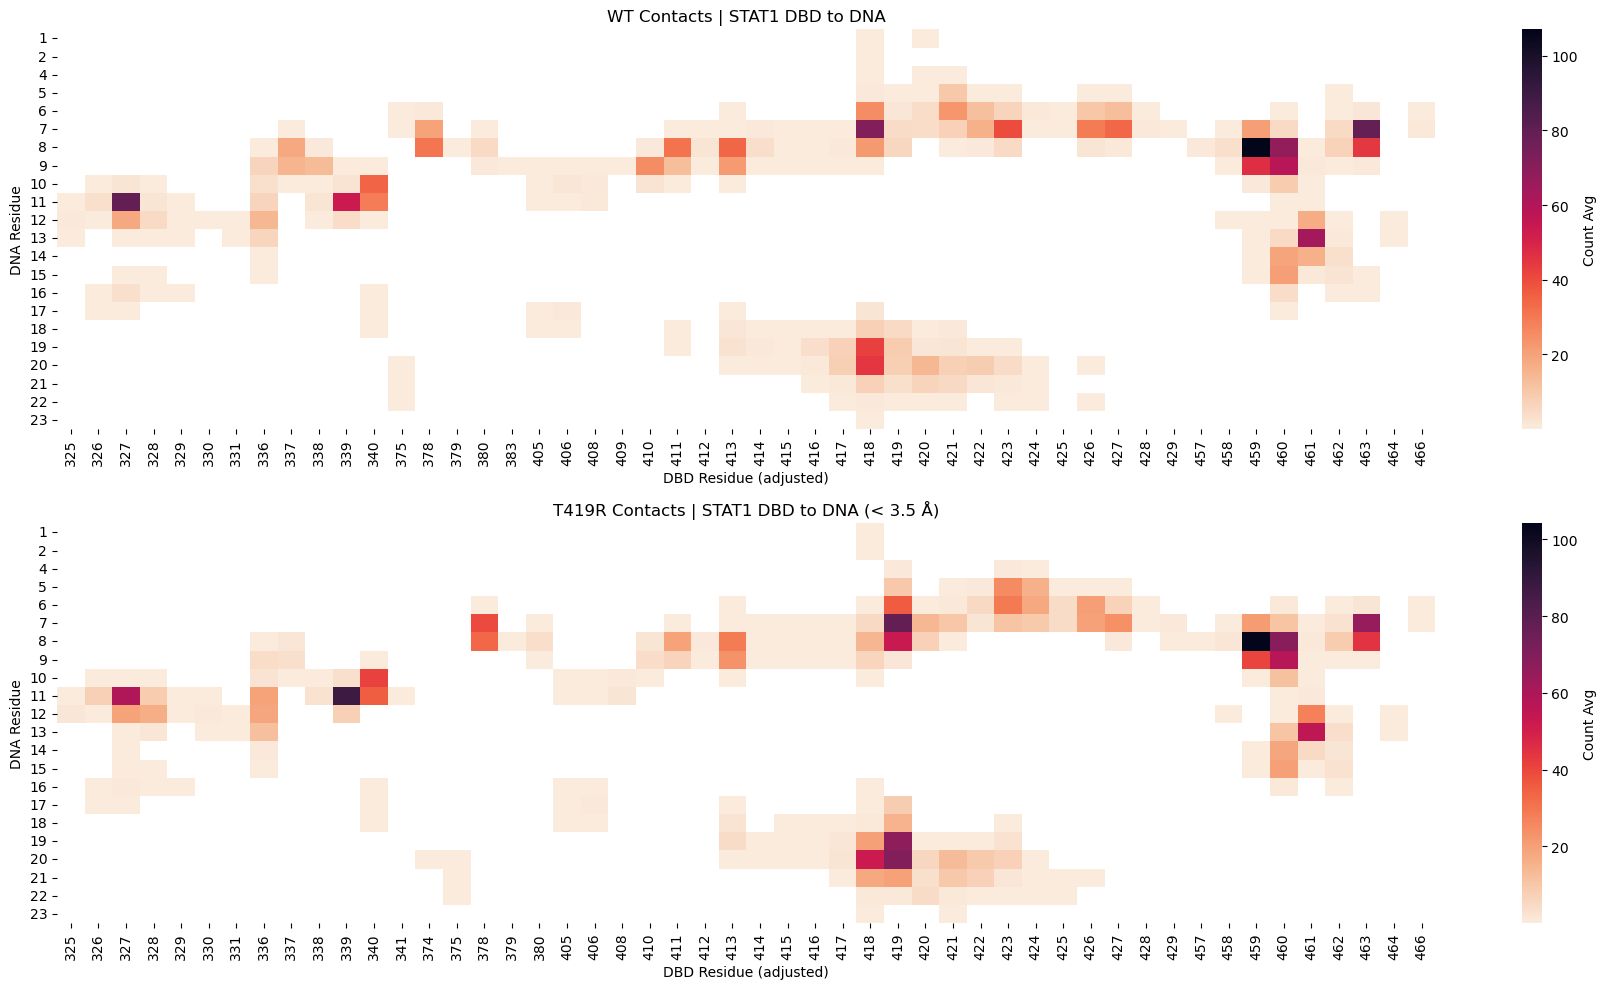

In [214]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_dbd_pivot_filtered, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 DBD to DNA')
ax1.set_xlabel('DBD Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T419R heatmap
sns.heatmap(mut_dbd_pivot_filtered, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('T419R Contacts | STAT1 DBD to DNA (< 3.5 Å)')
ax2.set_xlabel('DBD Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

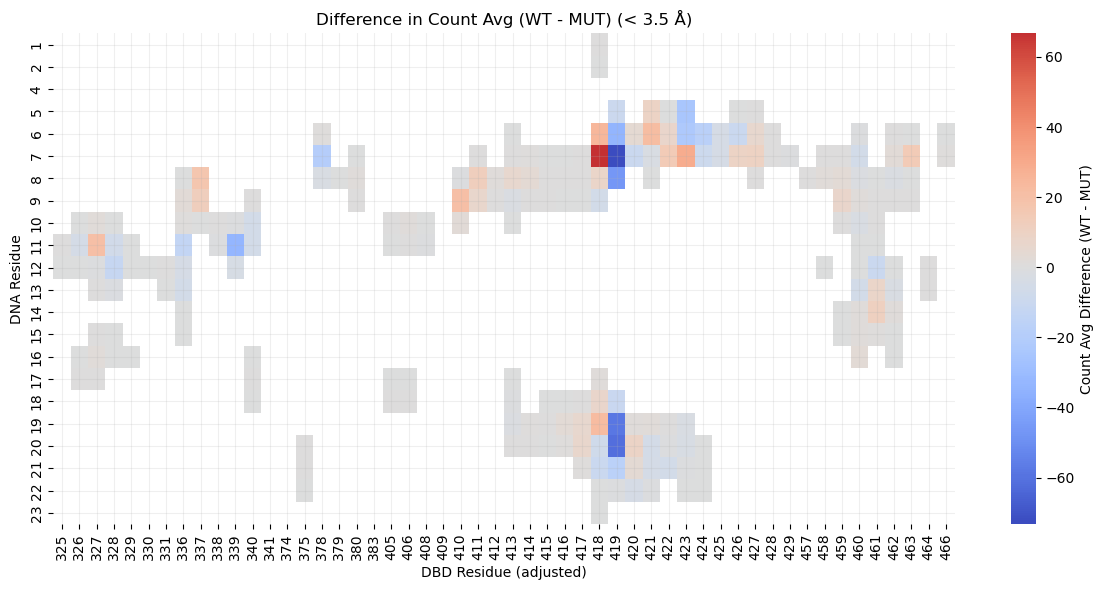

In [215]:
diff_dbd_pivot_filtered = wt_dbd_pivot_filtered - mut_dbd_pivot_filtered

plt.figure(figsize=(12, 6))

sns.heatmap(diff_dbd_pivot_filtered, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT) (< 3.5 Å)')
plt.xlabel('DBD Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

## Full protein with DNA

### Load data

In [216]:
wt_full_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/004.contacts/pairs_full.csv')
    wt_full_dfs.append(df)

T419R_full_dfs = []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/004.contacts/pairs_full.csv')
    T419R_full_dfs.append(df)

In [217]:
wt_full_dfs[0].head()

,frame,sel1_resid,sel1_resnm,sel2_resid,sel2_resnm,distance
0,1000,190,MET,12,DG,4.907506
1,1000,190,MET,12,DG,4.486903
2,1000,192,THR,12,DG,4.632156
3,1000,192,THR,11,DC,4.287577
4,1000,192,THR,11,DC,4.939452


### Preprocessing

Adjust residue numbers.

In [218]:
adjust_resid(wt_full_dfs + T419R_full_dfs)

In [219]:
wt_full_dfs[0].head()

,frame,sel1_resid,sel1_resnm,sel2_resid,sel2_resnm,distance,sel1_resid_adj,sel2_resid_adj
0,1000,190,MET,12,DG,4.907506,325,12
1,1000,190,MET,12,DG,4.486903,325,12
2,1000,192,THR,12,DG,4.632156,327,12
3,1000,192,THR,11,DC,4.287577,327,11
4,1000,192,THR,11,DC,4.939452,327,11


In [220]:
wt_full_agg = aggregate_pairs(wt_full_dfs)
T419R_full_agg = aggregate_pairs(T419R_full_dfs)

In [221]:
wt_full_agg.sort_values('count', ascending=False).head(10)

,sel1_resnm,sel1_resid_adj,sel2_resnm,sel2_resid_adj,count
314,SER,459,DT,8,401247
118,GLN,463,DT,7,290802
337,THR,327,DC,11,290273
32,ARG,418,DG,19,283033
36,ARG,418,DT,7,257178
89,ASN,460,DT,8,243777
392,VAL,461,DG,13,227767
90,ASN,460,DT,9,212553
375,VAL,339,DC,11,193456
315,SER,459,DT,9,173363


In [222]:
wt_full_agg["count_avg"] = wt_full_agg["count"] / (len(wt_full_dfs)* 1000)
T419R_full_agg["count_avg"] = T419R_full_agg["count"] / (len(T419R_full_dfs)* 1000)

In [223]:
wt_full_agg.sort_values('count_avg', ascending=False).head(10)

,sel1_resnm,sel1_resid_adj,sel2_resnm,sel2_resid_adj,count,count_avg
314,SER,459,DT,8,401247,133.749000
118,GLN,463,DT,7,290802,96.934000
337,THR,327,DC,11,290273,96.757667
32,ARG,418,DG,19,283033,94.344333
36,ARG,418,DT,7,257178,85.726000
89,ASN,460,DT,8,243777,81.259000
392,VAL,461,DG,13,227767,75.922333
90,ASN,460,DT,9,212553,70.851000
375,VAL,339,DC,11,193456,64.485333
315,SER,459,DT,9,173363,57.787667


In [224]:
T419R_full_agg.sort_values('count_avg', ascending=False).head(10)

,sel1_resnm,sel1_resid_adj,sel2_resnm,sel2_resid_adj,count,count_avg
300,SER,459,DT,8,387592,129.197333
52,ARG,419,DG,20,375678,125.226000
51,ARG,419,DG,19,322140,107.380000
344,VAL,339,DC,11,318216,106.072000
53,ARG,419,DT,7,271815,90.605000
90,ASN,460,DT,8,248777,82.925667
114,GLN,463,DT,7,244084,81.361333
26,ARG,418,DC,20,243926,81.308667
50,ARG,419,DG,6,217687,72.562333
321,THR,327,DC,11,216647,72.215667


### Comparison

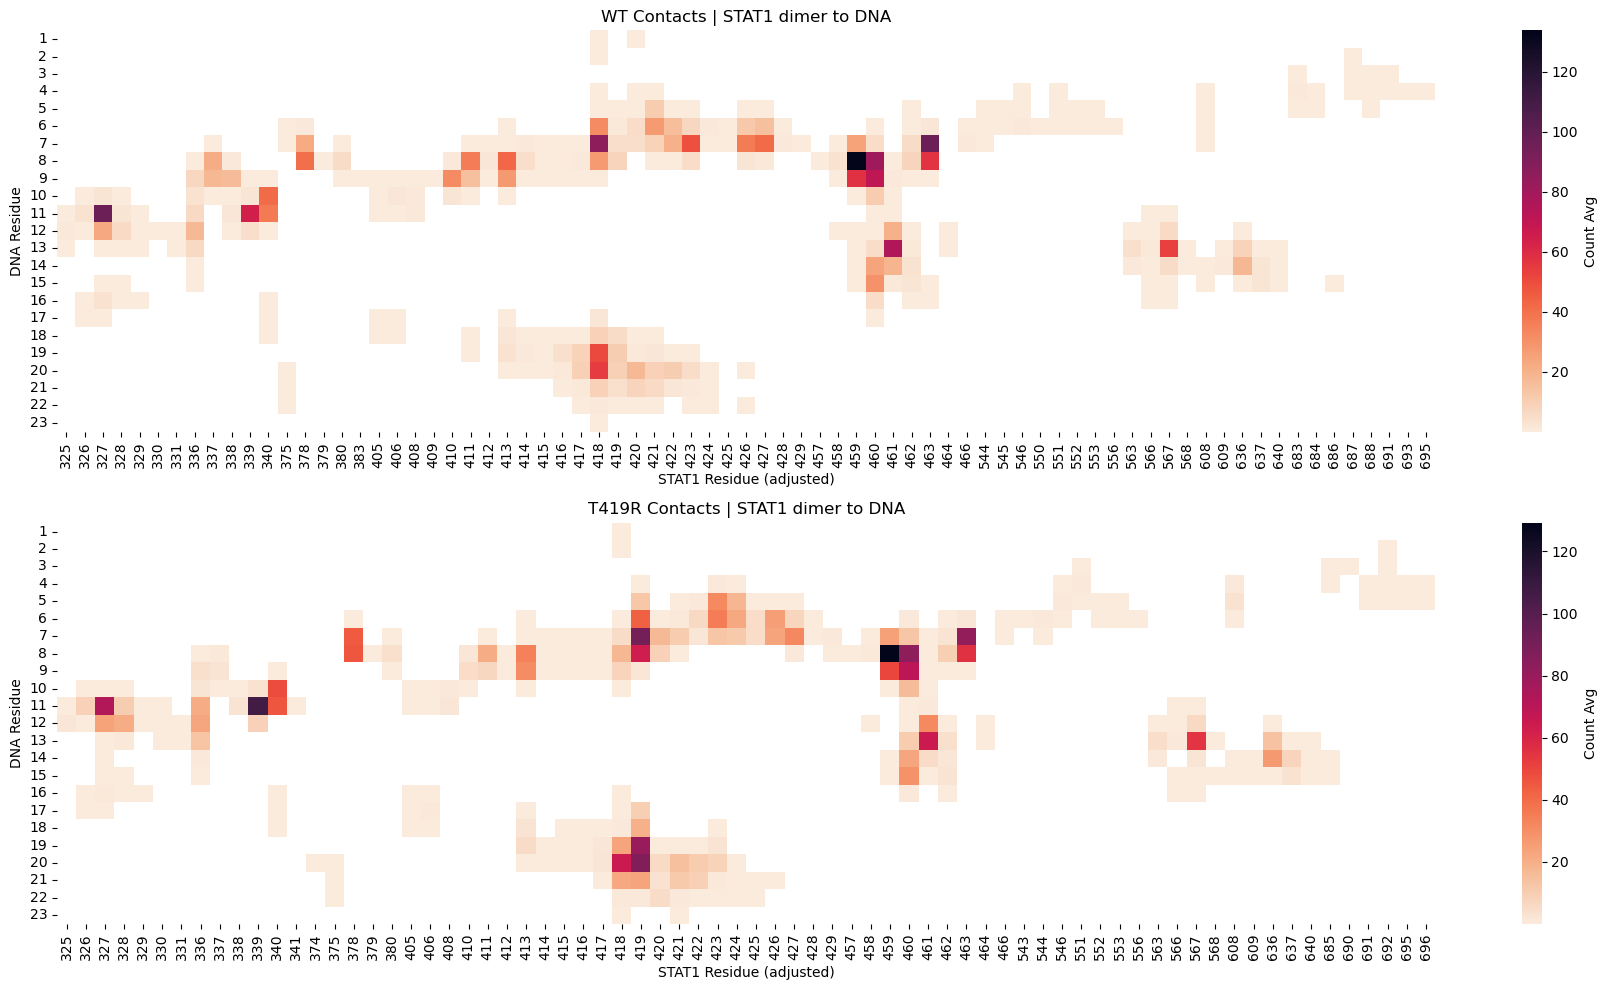

In [225]:
wt_full_pivot = pivotdf(wt_full_agg)
mut_full_pivot = pivotdf(T419R_full_agg)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 10), sharey=True)

# WT heatmap
sns.heatmap(wt_full_pivot, cmap='rocket_r', ax=ax1, cbar_kws={'label': 'Count Avg'})
ax1.set_title('WT Contacts | STAT1 dimer to DNA')
ax1.set_xlabel('STAT1 Residue (adjusted)')
ax1.set_ylabel('DNA Residue')

# T419R heatmap
sns.heatmap(mut_full_pivot, cmap='rocket_r', ax=ax2, cbar_kws={'label': 'Count Avg'})
ax2.set_title('T419R Contacts | STAT1 dimer to DNA')
ax2.set_xlabel('STAT1 Residue (adjusted)')
ax2.set_ylabel('DNA Residue')

plt.tight_layout()
plt.show()

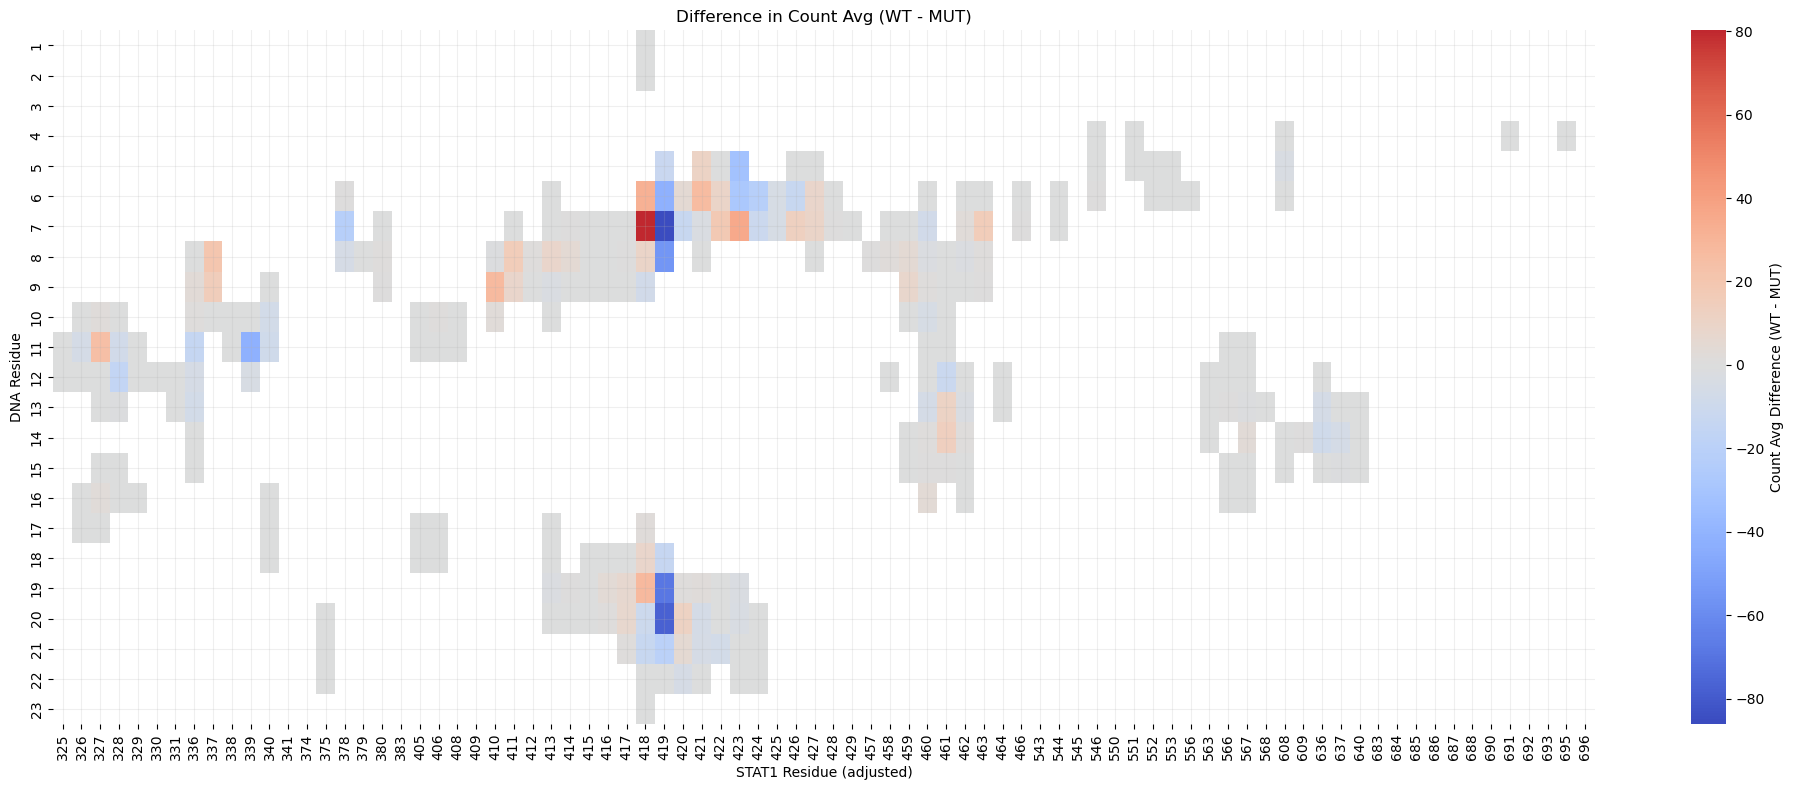

In [226]:
diff_full_pivot = wt_full_pivot - mut_full_pivot

plt.figure(figsize=(20, 8))

sns.heatmap(diff_full_pivot, cmap='coolwarm', center=0, cbar_kws={'label': 'Count Avg Difference (WT - MUT)'})
plt.title('Difference in Count Avg (WT - MUT)')
plt.xlabel('STAT1 Residue (adjusted)')
plt.ylabel('DNA Residue')

plt.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

## Conclusion

Most of the contacts under the 5 Å distance threshold happen between the DNA-binding domain (DBD) of STAT1 and the dsDNA. Although extending the analysis to the complete available protein structure reveals some contacts beyond this domain, particularly with residue LYS 567 in the linker domain and LYS 636 in the SH2 domain, their count average is relatively low. Furthermore, the difference in count average between WT and T419R in these domains is close to 0.

In the DBD, the greatest difference in count average between WT and T419R is observed in residues ARG 418 and 419. The contacts seem to shift from 418 towards 419 in the mutation. As a result, in T419R the number of contacts with 419 increases and with 418 decreases, as compared to the WT count average. This result is consistent with the change from uncharged threonine to positively charged arginine. The positively charged ARG interacts with the negatively charged DNA backbone, resulting is closer contacts. 

This difference remains when filtering out closer contacts (< 3.5 Å), some of which have already being considered as hydrogen bonds in a separate analysis, provided the atoms within this distance also fulfill the electrochemical and angle properties required to form such a bond. Although the distance filter might exclude some contacts that are not considered as potential hydrogen bonds, it also proves that the differences in contact distribution between WT and T419R go beyond short distances.